In [1]:
import torch
import torch.nn as nn
from torchvision import transforms
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

In [2]:
from PIL import Image
import pandas as pd
import os

In [3]:
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


In [4]:
path = '/content/gdrive/MyDrive/Colab Notebooks/Fashion_Peaks'
os.chdir(path)

2. Levantar el modelo en otro script para predecir

Cargámos el modelo:

In [6]:

# Asegurate de tener esta clase igual a la usada en el entrenamiento
class SpectraCNN(nn.Module):
    def __init__(self, n_classes=40):
        super(SpectraCNN, self).__init__()
        self.conv1 = nn.Conv2d(1, 16, kernel_size=3, padding=1)
        self.pool1 = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.pool2 = nn.MaxPool2d(2, 2)
        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.pool3 = nn.AdaptiveAvgPool2d((1, 1))
        self.fc1 = nn.Linear(64, 128)
        self.dropout = nn.Dropout(0.4)
        self.fc2 = nn.Linear(128, n_classes)

    def forward(self, x):
        x = self.pool1(torch.relu(self.conv1(x)))
        x = self.pool2(torch.relu(self.conv2(x)))
        x = self.pool3(torch.relu(self.conv3(x)))
        x = x.view(x.size(0), -1)
        x = self.dropout(torch.relu(self.fc1(x)))
        return self.fc2(x)


In [7]:

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = SpectraCNN(n_classes=41).to(device)
model.load_state_dict(torch.load("modelo_entrenado.pth", map_location=device))
model.eval()


SpectraCNN(
  (conv1): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool3): AdaptiveAvgPool2d(output_size=(1, 1))
  (fc1): Linear(in_features=64, out_features=128, bias=True)
  (dropout): Dropout(p=0.4, inplace=False)
  (fc2): Linear(in_features=128, out_features=41, bias=True)
)

In [8]:
df = pd.read_csv("imagenes_entrenamiento/labels.csv")
# Perdecir el área
def clase_a_valor(clase):
    return clase * 500 + 250

transform = transforms.Compose([
    transforms.Resize((46, 23)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5])
])


In [9]:

# Cargar imagen nueva

image_test = "spectro_01991.png"
img_path = "imagenes_entrenamiento/" + image_test
image = Image.open(img_path).convert('L')
image = transform(image).unsqueeze(0).to(device)  # [1,1,H,W]

# Predecir clase
with torch.no_grad():
    output = model(image)
    pred_clase = torch.argmax(output, dim=1).item()
    area_estimado = clase_a_valor(pred_clase)

print(f"Clase predicha: {pred_clase}")
print(f"Área estimada: {area_estimado}")
area_label = df[df["filename"] == image_test]["label"].values[0]
print(f"Área de {img_path}: {area_label}")


Clase predicha: 1
Área estimada: 750
Área de imagenes_entrenamiento/spectro_01991.png: 250


In [10]:
# Cargar imagen nueva
img_path = "imagenes_entrenamiento/spectro_00000.png"
image = Image.open(img_path).convert('L')
image = transform(image).unsqueeze(0).to(device)  # [1,1,H,W]

# Predecir clase
with torch.no_grad():
    output = model(image)
    pred_clase = torch.argmax(output, dim=1).item()
    area_estimado = clase_a_valor(pred_clase)

print(f"Clase predicha: {pred_clase}")
print(f"Área estimada: {area_estimado}")


Clase predicha: 21
Área estimada: 10750


In [11]:
# Vamos a comparar con los labels, solo por que los tenemos, normalmente la predicción no la podremos comparar
def clase_a_valor(clase):
    return clase * 500 + 250


In [12]:
from tqdm import tqdm  # barra de progreso

def evaluar_modelo_sobre_csv(model, csv_file, root_dir, transform):
    model.eval()

    df = pd.read_csv(csv_file)
    errores = []
    pred_areas = []
    reales = []

    for idx, row in tqdm(df.iterrows(), total=len(df)):
        #img_name = row[0]
        #area_real = row[1]
        img_name = row.iloc[0]
        area_real = row.iloc[1]


        img_path = os.path.join(root_dir, img_name)
        image = Image.open(img_path).convert('L')
        image = transform(image).unsqueeze(0).to(device)

        with torch.no_grad():
            output = model(image)
            pred_clase = torch.argmax(output, dim=1).item()
            area_predicha = clase_a_valor(pred_clase)

        error = abs(area_real - area_predicha)
        errores.append(error)
        pred_areas.append(area_predicha)
        reales.append(area_real)

    # Calcular estadísticas
    mae = sum(errores) / len(errores)
    print(f"\nEvaluación completada:")
    print(f"MAE (error absoluto medio): {mae:.2f} unidades")

    return reales, pred_areas, errores


In [13]:
# Este cálculo puede demorar más de 13 minutos
reales, predichos, errores = evaluar_modelo_sobre_csv(
    model=model,
    csv_file="imagenes_entrenamiento/labels.csv",
    root_dir="imagenes_entrenamiento",
    transform=transform
)


100%|██████████| 2000/2000 [12:57<00:00,  2.57it/s]


Evaluación completada:
MAE (error absoluto medio): 572.75 unidades


In [14]:
from collections import defaultdict
import numpy as np

errores_por_clase = defaultdict(list)
aciertos_por_clase = defaultdict(int)
total_por_clase = defaultdict(int)

for real, pred in zip(reales, predichos):
    clase_real = int((real - 1) // 500)
    clase_pred = int((pred - 1) // 500)

    error = abs(real - pred)
    errores_por_clase[clase_real].append(error)

    total_por_clase[clase_real] += 1
    if clase_real == clase_pred:
        aciertos_por_clase[clase_real] += 1


In [15]:
clases = sorted(total_por_clase.keys())
maes = [np.mean(errores_por_clase[c]) for c in clases]
accs = [aciertos_por_clase[c] / total_por_clase[c] for c in clases]
centros = [c * 500 + 250 for c in clases]  # valor medio del bin


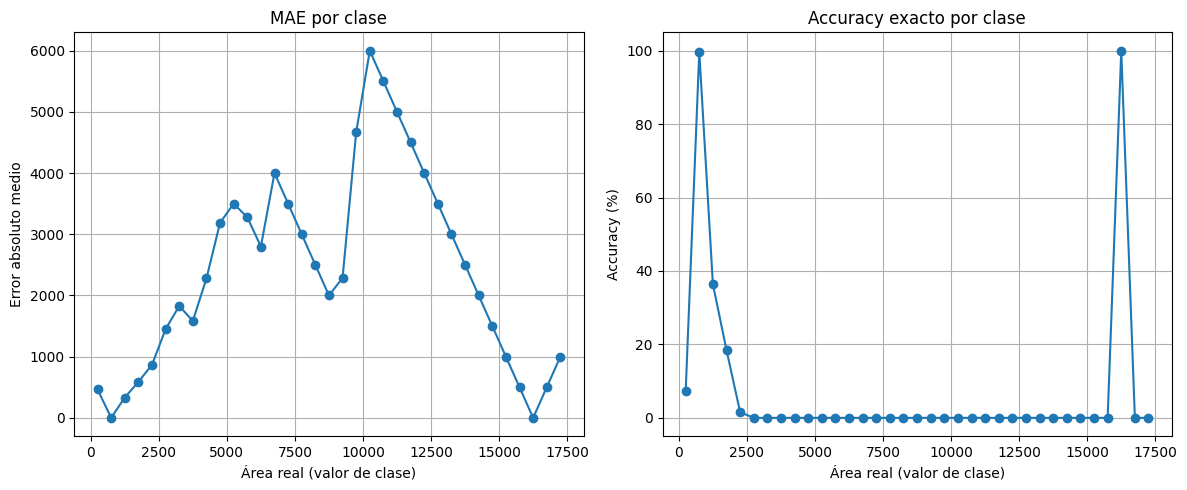

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(centros, maes, marker='o')
plt.title("MAE por clase")
plt.xlabel("Área real (valor de clase)")
plt.ylabel("Error absoluto medio")
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(centros, [a*100 for a in accs], marker='o')
plt.title("Accuracy exacto por clase")
plt.xlabel("Área real (valor de clase)")
plt.ylabel("Accuracy (%)")

plt.grid()

plt.tight_layout()
plt.show()


Buena pregunta, es un concepto clave.

---

### 📐 ¿Qué es el **MAE**?

**MAE** significa **Mean Absolute Error**, o en español: **Error Absoluto Medio**.

Se define como:

$$
\text{MAE} = \frac{1}{N} \sum_{i=1}^{N} | y_{\text{real}}^{(i)} - y_{\text{predicho}}^{(i)} |
$$

---

### 🧠 ¿Qué representa?

Es el **promedio de las diferencias absolutas** entre lo que el modelo predijo y el valor real. En tu caso:

* \$y\_{\text{real}}\$ = área real de la imagen (desde el CSV)
* \$y\_{\text{predicho}}\$ = área estimada a partir de la clase predicha

---

### ✅ ¿Qué te dice?

* Cuanto **más bajo el MAE**, **mejor la precisión** del modelo en promedio.
* A diferencia del MSE (error cuadrático medio), el MAE **no penaliza tanto los errores grandes**, y por eso es más interpretativo.
* Como está en **las mismas unidades que el valor que estimás** (el área), es **fácil de entender**: por ejemplo, un MAE de 300 significa que en promedio errás por 300 unidades de área.

---

Matriz de Confusión

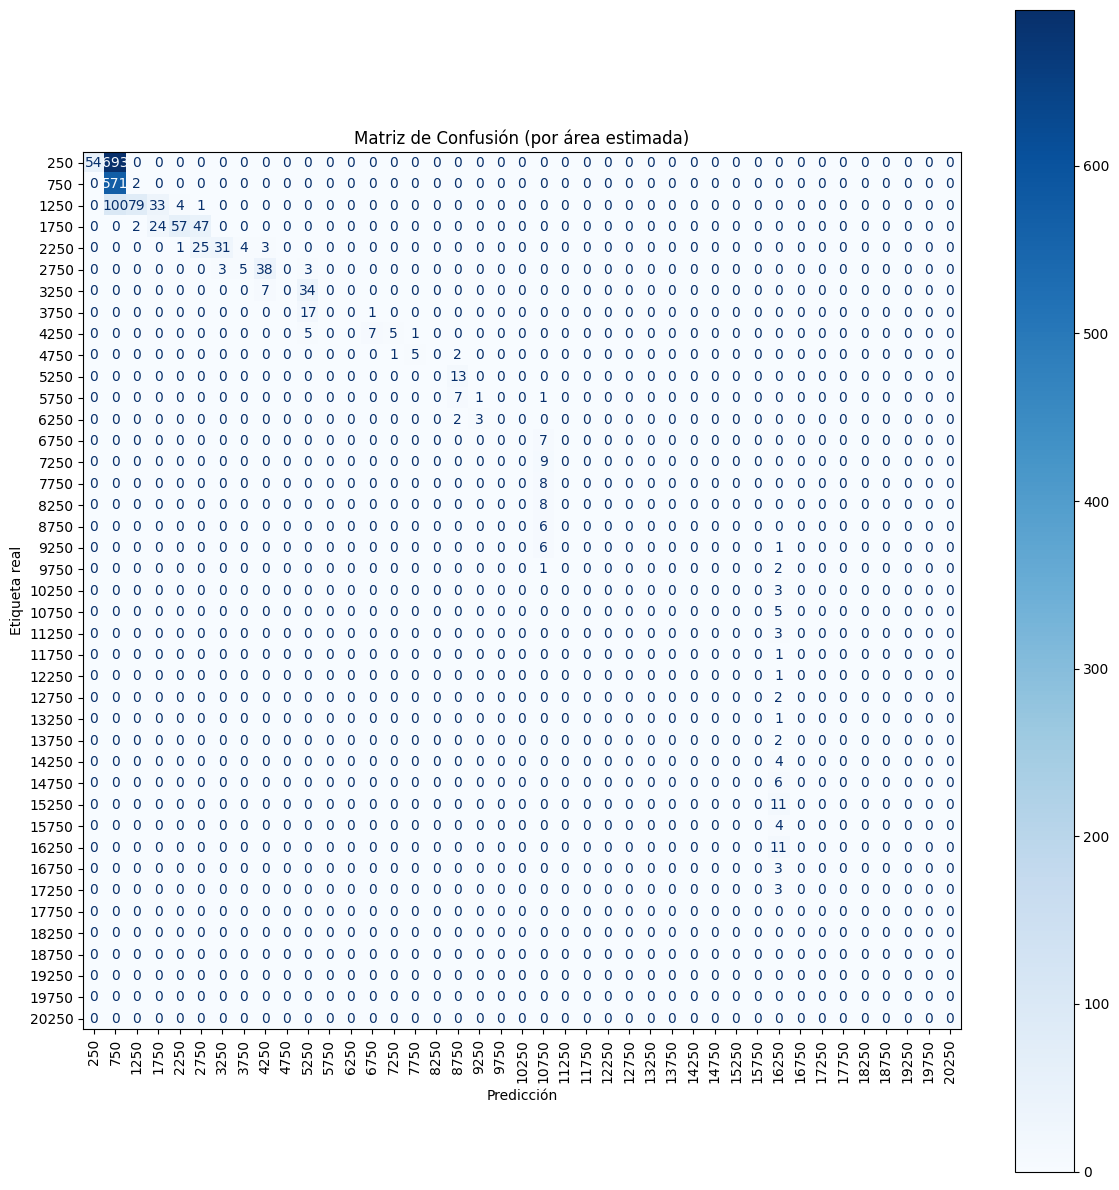

In [24]:
#import pandas as pd
#import torch
#from torchvision import transforms
#from PIL import Image
#import matplotlib.pyplot as plt

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Función para convertir clase a área
def clase_a_valor(clase):
    return clase * 500 + 250

# Transformación usada en las imágenes
transform = transforms.Compose([
    transforms.Resize((46, 23)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5])
])

# Cargar modelo
model = SpectraCNN(n_classes=41).to(device)
model.load_state_dict(torch.load("modelo_entrenado.pth", map_location=device))
model.eval()

# Cargar CSV con labels
df = pd.read_csv("imagenes_entrenamiento/labels.csv")

# Listas para acumular verdaderos y predichos
true_labels = []
pred_labels = []

# Recorrer cada imagen
for idx, row in df.iterrows():
    img_path = "imagenes_entrenamiento/" + row["filename"]
    label = row["label"]

    # Convertir valor de área a clase entera (0 a 40)
    clase_real = int((label - 250) / 500)

    try:
        image = Image.open(img_path).convert('L')
    except:
        print(f"No se pudo abrir {img_path}, se salta.")
        continue

    image = transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        output = model(image)
        pred = torch.argmax(output, dim=1).item()

    true_labels.append(clase_real)
    pred_labels.append(pred)

# Generar matriz de confusión
# Aseguramos que solo se consideren las clases del 0 al 40
labels = list(range(41))
cm = confusion_matrix(true_labels, pred_labels, labels=labels)
# Etiquetas en unidades de área
area_labels = [clase_a_valor(i) for i in labels]


# Mostrar como heatmap con etiquetas de área
# Crear figura grande antes de dibujar la matriz
plt.figure(figsize=(12, 12))  # Podés ajustar los valores a gusto

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=area_labels)
disp.plot(xticks_rotation=90, cmap='Blues', ax=plt.gca())  # usar el eje actual

plt.title("Matriz de Confusión (por área estimada)")
plt.xlabel("Predicción")
plt.ylabel("Etiqueta real")
plt.tight_layout()
plt.savefig("matriz_confusion.png", dpi=300)
plt.show()


In [25]:
df_cm = pd.DataFrame(cm, index=area_labels, columns=area_labels)
df_cm.to_csv("matriz_confusion_areas.csv")
